# Text-to-Image Generation with a Pretrained Stable Diffusion Model

**Name:** Sanskar Meharkar  **PRN:** <your PRN>

In this notebook we use a pretrained Stable Diffusion model (`segmind/tiny-sd`, a distilled version of Stable Diffusion) from the Hugging Face **Diffusers** library to generate images from text prompts.
We then study how the following settings change the output:

1. **Number of inference steps** (`num_inference_steps`): how many times the model removes noise from the image
2. **Guidance scale** (`guidance_scale`): how strongly the image is pushed to follow the text prompt
3. **Prompt design and negative prompts**
4. **Sampling method (scheduler)**: PNDM, DDIM, Euler, Euler Ancestral and DPM-Solver++

> Use a GPU: *Runtime > Change runtime type > T4 GPU*, then *Runtime > Run all*.
> The last cell builds the PDF report from the results of this run.

## 1. Install libraries and student details

In [1]:
!pip install -q --upgrade diffusers accelerate transformers safetensors huggingface_hub reportlab

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


In [2]:
import os, time, json
os.makedirs("figs", exist_ok=True)       # every figure is also saved here for the PDF report
RESULTS = {}                              # every measured number is collected here

# Fill these in - they appear on the PDF report
STUDENT = dict(
    name="Sanskar Meharkar",
    prn="<your PRN>",
    batch="<your batch>",
    github="<your GitHub link>",
    colab="<your Colab link>",
)

## 2. Load the pretrained model

In [3]:
import torch
from diffusers import DiffusionPipeline
import matplotlib.pyplot as plt

model_id = "segmind/tiny-sd"

pipe = DiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")
pipe.set_progress_bar_config(disable=True)   # hide the per-image progress bar

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


> **Note:** a warning about the VAE `diffusion_pytorch_model.safetensors` file may appear. It is harmless: the library falls back to another weight file and the model still loads correctly.

In [4]:
print(f"Is CUDA available?: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device name: {torch.cuda.get_device_name(0)}")
    RESULTS["gpu"] = f"Google Colab {torch.cuda.get_device_name(0)} GPU"

Is CUDA available?: True
Device name: Tesla T4


### 2.1 Components of the Stable Diffusion pipeline

A Stable Diffusion pipeline is made of four main parts that work together:

| Component | Class | Role |
|---|---|---|
| **Text encoder** | `CLIPTextModel` (+ tokenizer) | Converts the text prompt into numerical embeddings that the U-Net can use as a condition. |
| **U-Net** | `UNet2DConditionModel` | The denoising network. At every step it predicts the noise in the latent image, guided by the text embeddings. |
| **Scheduler** | e.g. `PNDMScheduler` | The sampling method. It decides the noise levels over the steps and how the predicted noise is removed at each step. |
| **VAE** | `AutoencoderKL` | Works in a compressed *latent space*. The decoder turns the final latent into a full-size RGB image. |

**Pipeline flow:** prompt -> text encoder -> embeddings. Random noise (latent) -> U-Net + scheduler repeated for N steps (with classifier-free guidance) -> clean latent -> VAE decoder -> final image.
Working in latent space (8x smaller in each dimension) makes Stable Diffusion much faster than diffusing in pixel space.

In [5]:
print("Text encoder :", type(pipe.text_encoder).__name__)
print("Tokenizer    :", type(pipe.tokenizer).__name__)
print("U-Net        :", type(pipe.unet).__name__)
print("Scheduler    :", type(pipe.scheduler).__name__)
print("VAE          :", type(pipe.vae).__name__)

def n_params(m): return sum(p.numel() for p in m.parameters()) / 1e6
print(f"\nParameters (millions) -> text encoder: {n_params(pipe.text_encoder):.0f}, "
      f"U-Net: {n_params(pipe.unet):.0f}, VAE: {n_params(pipe.vae):.0f}")

RESULTS["components"] = dict(text_encoder=type(pipe.text_encoder).__name__, unet=type(pipe.unet).__name__,
                             scheduler=type(pipe.scheduler).__name__, vae=type(pipe.vae).__name__)

# keep the default scheduler so we can restore it after the scheduler experiment
DefaultScheduler = type(pipe.scheduler)
default_scheduler_config = pipe.scheduler.config

Text encoder : CLIPTextModel
Tokenizer    : CLIPTokenizer
U-Net        : UNet2DConditionModel
Scheduler    : DPMSolverMultistepScheduler
VAE          : AutoencoderKL

Parameters (millions) -> text encoder: 123, U-Net: 323, VAE: 84


## 3. Generate an image from a text prompt

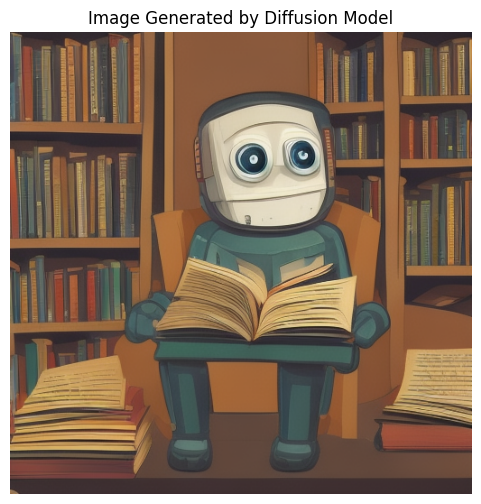

In [6]:
prompt = "A cartoon robot reading a book in a cozy library"
RESULTS["prompt"] = prompt

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5,
    generator=torch.Generator("cuda").manual_seed(42)
).images[0]

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis('off')
plt.title("Image Generated by Diffusion Model")
plt.savefig("figs/base.png", dpi=110, bbox_inches="tight")
plt.show()

**Observation:** The generated image should show a cartoon-style robot reading a book in a library, matching the prompt. Small details (fingers, book pages, shelf contents) are usually not perfect in a small distilled model.

## 4. Helper functions

To compare settings fairly we use the **same random seed** every time. Then the only thing that changes between images is the setting we are testing.
A short warm-up run is done first so that the one-time GPU start-up cost does not distort the timing of the first experiment.

In [7]:
def generate(prompt, steps=25, guidance=7.5, seed=42, negative_prompt=None):
    generator = torch.Generator("cuda").manual_seed(seed)   # same seed = same starting noise
    torch.cuda.synchronize()
    start = time.time()
    img = pipe(
        prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        guidance_scale=guidance,
        generator=generator
    ).images[0]
    torch.cuda.synchronize()
    return img, time.time() - start


def show_images(images, titles, fname=None, figsize=(20, 5)):
    fig = plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
    if fname:
        plt.savefig(f"figs/{fname}.png", dpi=90, bbox_inches="tight")
    plt.show()

_ = generate(prompt, steps=2)   # warm-up (result ignored)

## 5. Experiment 1: Effect of the number of inference steps

The model starts from pure noise and removes a little noise at every step. We keep `guidance_scale = 7.5` fixed and change only the number of steps.

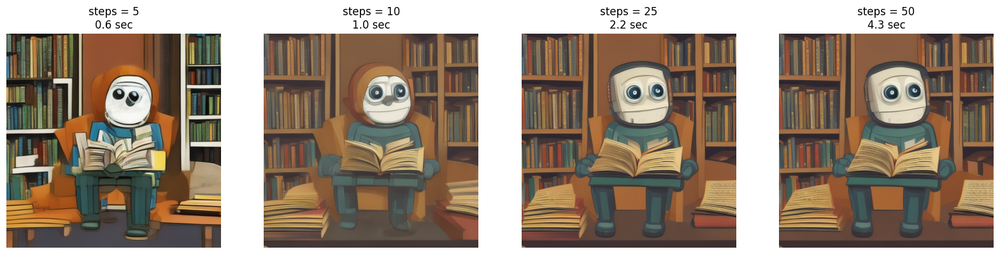

In [8]:
steps_list = [5, 10, 25, 50]
step_imgs, titles, step_times = [], [], []

for s in steps_list:
    img, t = generate(prompt, steps=s, guidance=7.5)
    step_imgs.append(img)
    step_times.append(t)
    titles.append(f"steps = {s}\n{t:.1f} sec")

show_images(step_imgs, titles, fname="steps")

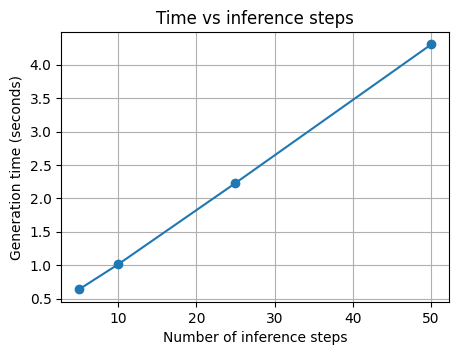

In [9]:
plt.figure(figsize=(5, 3.5))
plt.plot(steps_list, step_times, marker="o")
plt.xlabel("Number of inference steps")
plt.ylabel("Generation time (seconds)")
plt.title("Time vs inference steps")
plt.grid(True)
plt.savefig("figs/time_vs_steps.png", dpi=110, bbox_inches="tight")
plt.show()

**Observations** *(general behaviour - confirm against your own images)*

- With very few steps (5) the noise is not removed enough, so shapes look rough or unfinished and fine details are missing.
- Between about 10 and 25 steps the structure and detail improve clearly.
- Beyond about 25 steps the visible improvement is very small, while the generation time keeps growing roughly linearly with the number of steps.
- This is a quality vs. speed trade-off; about 20 to 30 steps is usually a good choice for this model.

## 6. Experiment 2: Effect of the guidance scale

The guidance scale controls how closely the image follows the text prompt (classifier-free guidance). We keep `steps = 25` fixed and change only the guidance scale.

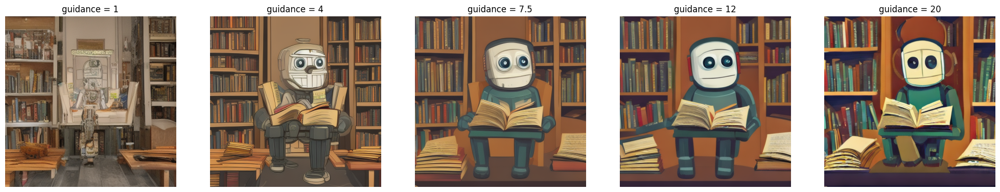

In [10]:
guidance_list = [1, 4, 7.5, 12, 20]
guid_imgs, titles = [], []

for g in guidance_list:
    img, t = generate(prompt, steps=25, guidance=g)
    guid_imgs.append(img)
    titles.append(f"guidance = {g}")

show_images(guid_imgs, titles, fname="guidance", figsize=(25, 5))

**Observations** *(general behaviour - confirm against your own images)*

- Guidance 1: classifier-free guidance is effectively off, so the image follows the prompt only weakly and often looks messy or off-topic.
- Low values (about 3 to 4): the subject is usually recognisable, but the image can look flat or washed out.
- Medium values (about 7 to 12): the best balance between following the prompt and natural colours and details.
- Very high values (15 to 20): contrast and saturation increase, the image looks over-processed and unwanted artefacts may appear.
- A higher guidance scale therefore does not always give a better image.

## 7. Experiment 3: Effect of changing the prompt

We keep steps and guidance fixed (25 and 7.5) and only change the text.

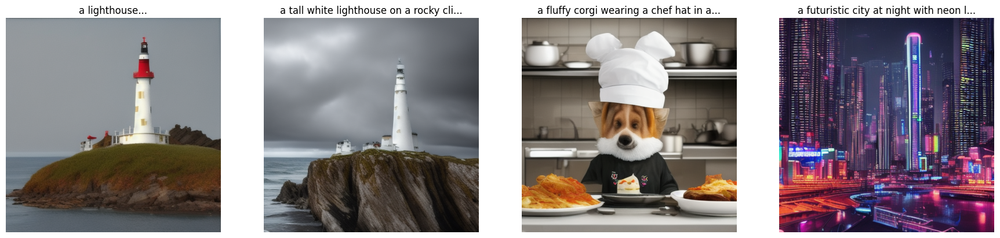

In [11]:
prompts = [
    "a lighthouse",
    "a tall white lighthouse on a rocky cliff, stormy sea, dramatic clouds, seagulls, high quality",
    "a fluffy corgi wearing a chef hat in a kitchen, digital art",
    "a futuristic city at night with neon lights, realistic photo",
]
RESULTS["prompts"] = prompts

images, titles = [], []
for p in prompts:
    img, t = generate(p, steps=25, guidance=7.5)
    images.append(img)
    titles.append(p[:38] + "...")

show_images(images, titles, fname="prompts", figsize=(22, 5))

**Observations** *(general behaviour - confirm against your own images)*

- A very short prompt leaves most choices to the model, so the result is generic.
- A detailed prompt gives more control over the content, but a small distilled model may still miss some of the small objects requested.
- Style words such as 'realistic photo' or 'digital art' clearly change the overall look of the image.
- More descriptive prompts give more control over the output.

## 8. Experiment 4: Prompt engineering and negative prompts

A good prompt usually has the structure: **subject + details + style + lighting + quality words**.
A **negative prompt** tells the model what to avoid. It is used in classifier-free guidance as the "unconditional" direction, so the model is pushed away from those concepts.
(Note: negative prompts have no effect when `guidance_scale = 1`, because guidance is turned off.)

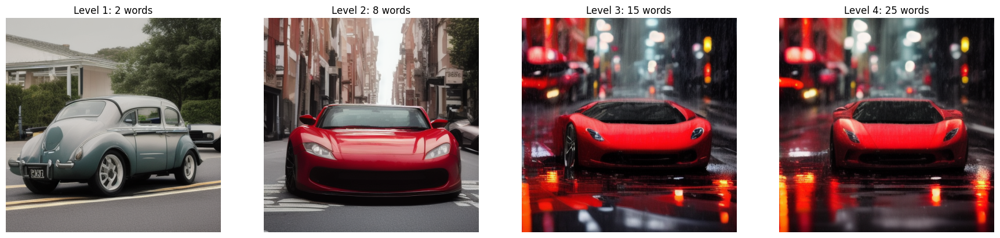

Level 1: a car
Level 2: a red sports car parked on a street
Level 3: a red sports car parked on a wet street at night, neon reflections, realistic photo
Level 4: a red sports car parked on a wet street at night, neon reflections, cinematic lighting, shallow depth of field, professional photography, highly detailed, sharp focus


In [12]:
# 8.1 Progressively better prompts (same subject, same seed)
prompt_levels = [
    "a car",
    "a red sports car parked on a street",
    "a red sports car parked on a wet street at night, neon reflections, realistic photo",
    "a red sports car parked on a wet street at night, neon reflections, cinematic lighting, "
    "shallow depth of field, professional photography, highly detailed, sharp focus",
]
RESULTS["prompt_levels"] = prompt_levels

images, titles = [], []
for i, p in enumerate(prompt_levels):
    img, _ = generate(p, steps=25, guidance=7.5)
    images.append(img)
    titles.append(f"Level {i+1}: {len(p.split())} words")
show_images(images, titles, fname="prompt_levels", figsize=(22, 5))
for i, p in enumerate(prompt_levels):
    print(f"Level {i+1}: {p}")

**Observations (prompt structure)** *(general behaviour - confirm against your own images)*

- Adding subject details, then style and lighting words, then quality words should make the image progressively more specific, better lit and sharper.
- Very short prompts leave many choices to the model, so the result is less controlled.

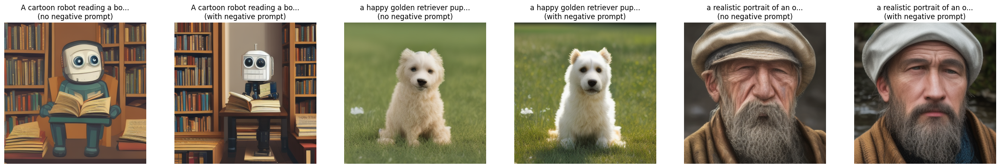

Negative prompt used: blurry, low quality, distorted, deformed, extra limbs, bad anatomy, watermark, text


In [13]:
# 8.2 Effect of a negative prompt (same prompt, same seed, same settings)
neg = "blurry, low quality, distorted, deformed, extra limbs, bad anatomy, watermark, text"
RESULTS["neg"] = neg

test_prompts = [
    "A cartoon robot reading a book in a cozy library",
    "a happy golden retriever puppy sitting on grass, digital art",
    "a realistic portrait of an old fisherman, detailed face",
]

images, titles = [], []
for p in test_prompts:
    img_a, _ = generate(p, steps=25, guidance=7.5)
    img_b, _ = generate(p, steps=25, guidance=7.5, negative_prompt=neg)
    images += [img_a, img_b]
    titles += [p[:28] + "...\n(no negative prompt)", p[:28] + "...\n(with negative prompt)"]

show_images(images, titles, fname="negative", figsize=(30, 5.5))
print("Negative prompt used:", neg)

**Observations (negative prompts)** *(general behaviour - confirm against your own images)*

- A negative prompt pushes the image away from the listed concepts (blur, distortion, extra limbs, watermark ...).
- With the same seed the main subject stays the same; the change is usually small but useful (cleaner details and anatomy).
- It helps most for people and animals, where anatomy errors are common, and has no effect when guidance scale = 1.

## 9. Experiment 5: Effect of the sampling method (scheduler)

The **scheduler** (sampler) decides how the noise is removed at every step. All schedulers use the same U-Net, but they differ in the maths used for each step, so they differ in **speed, quality at low step counts, and randomness**.

| Scheduler | Short description |
|---|---|
| **PNDM** | Pseudo numerical method, the default for Stable Diffusion v1. Good quality, deterministic. |
| **DDIM** | Deterministic version of DDPM. Allows few steps, gives consistent results for the same seed. |
| **Euler** | Simple and fast ODE solver, deterministic. |
| **Euler Ancestral (Euler-A)** | Adds fresh noise at each step, so it never fully "converges"; the image keeps changing with the step count. More creative, less predictable. |
| **DPM-Solver++ (DPM++)** | High-order solver that gives good quality in only 15 to 25 steps. |

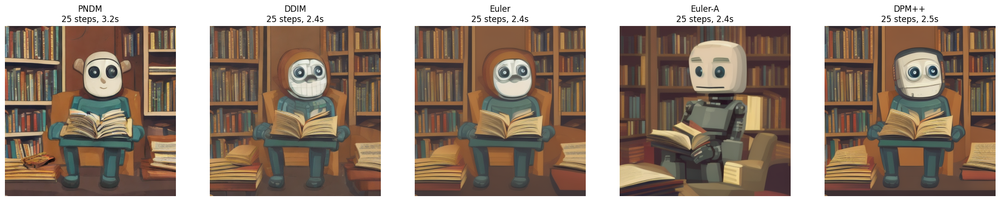

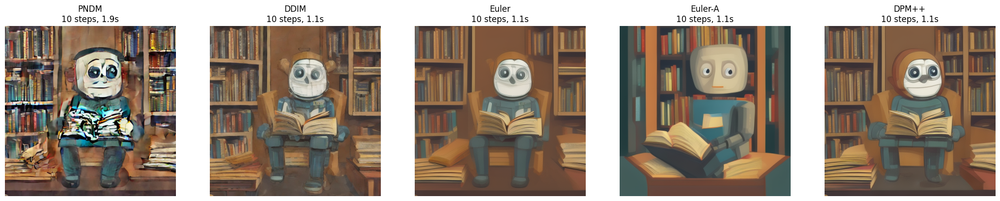

In [14]:
from diffusers import (PNDMScheduler, DDIMScheduler, EulerDiscreteScheduler,
                       EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler)

schedulers = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler-A": EulerAncestralDiscreteScheduler,
    "DPM++": DPMSolverMultistepScheduler,
}

def run_schedulers(steps, prompt=prompt):
    imgs, titles, times = [], [], []
    for name, cls in schedulers.items():
        pipe.scheduler = cls.from_config(default_scheduler_config)
        img, t = generate(prompt, steps=steps, guidance=7.5)
        imgs.append(img); times.append(t)
        titles.append(f"{name}\n{steps} steps, {t:.1f}s")
    return imgs, titles, times

# 9.1 Same number of steps (25)
imgs_25, titles_25, times_25 = run_schedulers(25)
show_images(imgs_25, titles_25, fname="sched25", figsize=(26, 5.5))

# 9.2 Few steps (10): which sampler gives a good image fastest?
imgs_10, titles_10, times_10 = run_schedulers(10)
show_images(imgs_10, titles_10, fname="sched10", figsize=(26, 5.5))

# restore the model's own default scheduler for the remaining experiments
pipe.scheduler = DefaultScheduler.from_config(default_scheduler_config)

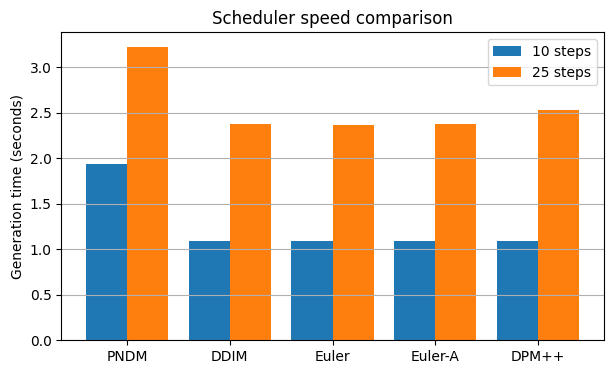

In [15]:
# Speed comparison of schedulers
names = list(schedulers.keys())
x = range(len(names))
plt.figure(figsize=(7, 4))
plt.bar([i - 0.2 for i in x], times_10, width=0.4, label="10 steps")
plt.bar([i + 0.2 for i in x], times_25, width=0.4, label="25 steps")
plt.xticks(list(x), names)
plt.ylabel("Generation time (seconds)")
plt.title("Scheduler speed comparison")
plt.legend(); plt.grid(axis="y")
plt.savefig("figs/sched_time.png", dpi=110, bbox_inches="tight")
plt.show()

**Observations (schedulers)** *(general behaviour - confirm against your own images)*

- With the same number of steps all samplers give a similar scene from the same starting noise, but details, contrast and texture differ slightly because each follows a different path from noise to image.
- At a low step count (10), higher-order solvers such as DPM-Solver++ (and DDIM / Euler) generally reach a clean image sooner than PNDM.
- Euler Ancestral adds fresh noise at every step, so it is stochastic and its image keeps changing with the step count.
- The time per step is almost the same for all schedulers because the U-Net dominates the cost; a better sampler is faster only because it needs fewer steps for the same quality.

## 10. Combined effect: steps and guidance together

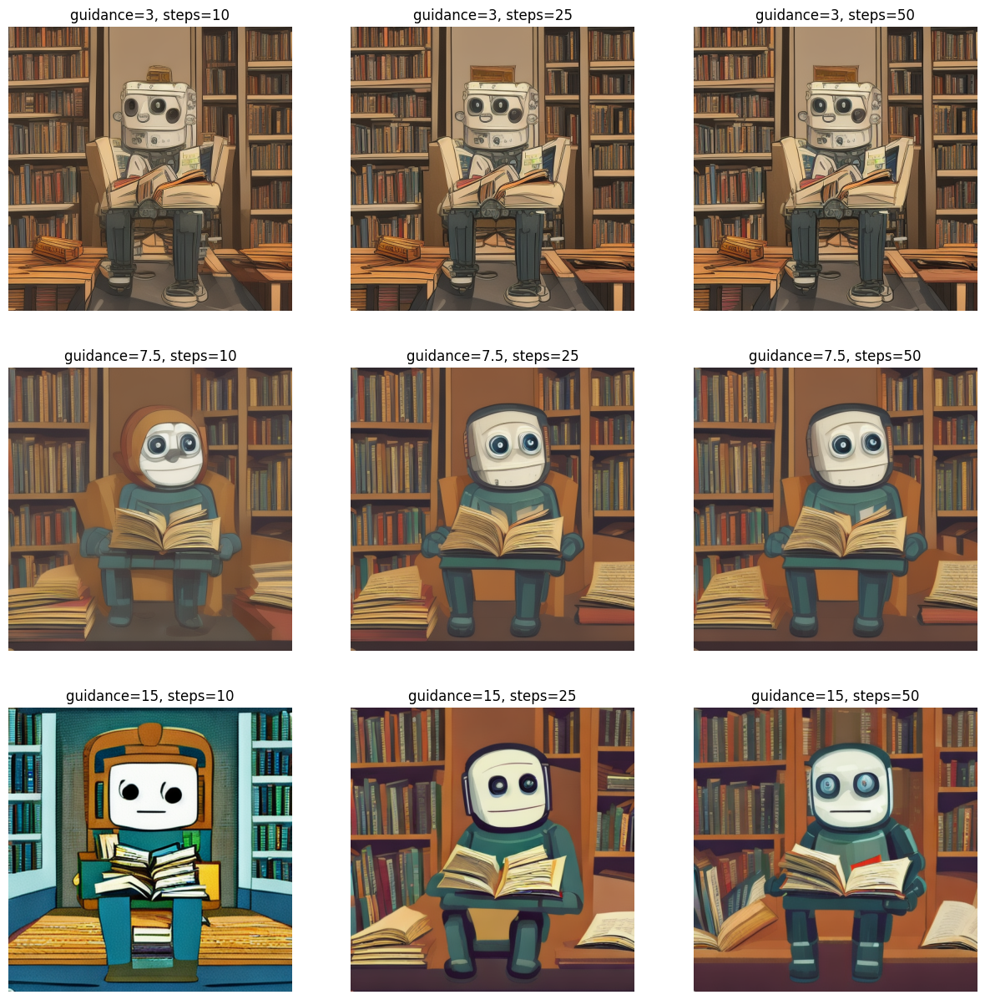

In [16]:
steps_values = [10, 25, 50]
guidance_values = [3, 7.5, 15]

plt.figure(figsize=(15, 15))
k = 1
for g in guidance_values:
    for s in steps_values:
        img, _ = generate(prompt, steps=s, guidance=g)
        plt.subplot(3, 3, k)
        plt.imshow(img)
        plt.title(f"guidance={g}, steps={s}")
        plt.axis('off')
        k += 1
plt.savefig("figs/grid.png", dpi=70, bbox_inches="tight")
plt.show()

**Observations** *(general behaviour - confirm against your own images)*

- Steps and guidance work together: steps control how well the noise is cleaned, guidance controls how strongly the prompt is followed.
- Low guidance is not fixed by adding more steps; high guidance stays harsh even with many steps; very few steps give unfinished images at any guidance.
- The best results are usually in the middle: guidance about 7.5 with about 25 steps.

## 11. Quantitative check: CLIP score

So far the comparison was visual. We can also measure **prompt-image similarity** with a CLIP model (higher score = the image matches the text better). This is only a rough indicator, but it can support the visual observations.
The scores below are computed from the images already generated above.

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

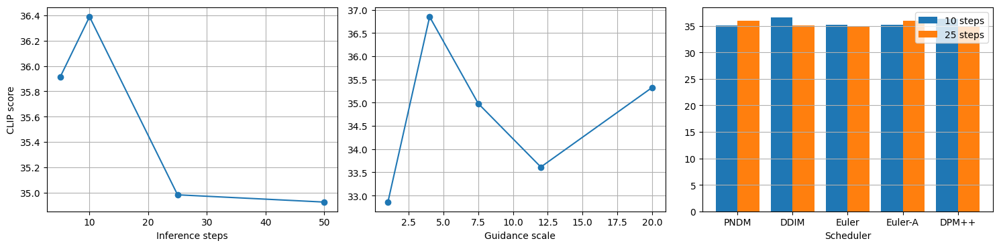

Steps   : {5: 35.9, 10: 36.4, 25: 35.0, 50: 34.9}
Guidance: {1: 32.9, 4: 36.8, 7.5: 35.0, 12: 33.6, 20: 35.3}
Sched 10: {'PNDM': 35.1, 'DDIM': 36.6, 'Euler': 35.2, 'Euler-A': 35.3, 'DPM++': 36.4}
Sched 25: {'PNDM': 35.9, 'DDIM': 35.1, 'Euler': 34.8, 'Euler-A': 36.0, 'DPM++': 35.0}


In [17]:
from transformers import CLIPProcessor, CLIPModel

clip_id = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_id).to("cuda").eval()
clip_proc = CLIPProcessor.from_pretrained(clip_id)

@torch.no_grad()
def clip_score(img, text):
    inputs = clip_proc(text=[text], images=img, return_tensors="pt", padding=True).to("cuda")
    return clip_model(**inputs).logits_per_image.item()      # cosine similarity * 100

s_scores  = [clip_score(im, prompt) for im in step_imgs]
g_scores  = [clip_score(im, prompt) for im in guid_imgs]
sc25      = [clip_score(im, prompt) for im in imgs_25]
sc10      = [clip_score(im, prompt) for im in imgs_10]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(steps_list, s_scores, marker="o"); ax[0].set_xlabel("Inference steps"); ax[0].set_ylabel("CLIP score"); ax[0].grid(True)
ax[1].plot(guidance_list, g_scores, marker="o"); ax[1].set_xlabel("Guidance scale"); ax[1].grid(True)
ax[2].bar([i - 0.2 for i in range(len(names))], sc10, width=0.4, label="10 steps")
ax[2].bar([i + 0.2 for i in range(len(names))], sc25, width=0.4, label="25 steps")
ax[2].set_xticks(range(len(names))); ax[2].set_xticklabels(names); ax[2].set_xlabel("Scheduler"); ax[2].legend(); ax[2].grid(axis="y")
plt.tight_layout()
plt.savefig("figs/clip.png", dpi=110, bbox_inches="tight")
plt.show()

print("Steps   :", dict(zip(steps_list, [round(v, 1) for v in s_scores])))
print("Guidance:", dict(zip(guidance_list, [round(v, 1) for v in g_scores])))
print("Sched 10:", dict(zip(names, [round(v, 1) for v in sc10])))
print("Sched 25:", dict(zip(names, [round(v, 1) for v in sc25])))

# collect everything the PDF report needs
RESULTS["steps"]    = dict(steps=steps_list, times=step_times, clip=s_scores)
RESULTS["guidance"] = dict(values=guidance_list, clip=g_scores)
RESULTS["sched"]    = dict(names=names, t10=times_10, t25=times_25, clip10=sc10, clip25=sc25)
json.dump(RESULTS, open("results.json", "w"), indent=2)

**Observations (CLIP score)**

The CLIP score measures only prompt-image similarity (higher = better match), not beauty or realism. It is a rough indicator: with a single seed, differences of 1 to 2 points are within noise, so it must be used together with visual inspection.

## 12. Conclusion

| Setting | Too low | Good range | Too high |
|---|---|---|---|
| Inference steps | Rough, distorted shapes, missing details | about 20 to 30 | Very little extra quality, much slower |
| Guidance scale | Ignores the prompt, messy image | about 7 to 12 | Over-saturated, harsh contrast, unwanted objects |
| Prompt detail | Generic image, random choices by the model | Subject + style + lighting + quality words | Too many words may be ignored by a small model |
| Negative prompt | - | Short list of unwanted qualities | Not useful if guidance is 1 |
| Scheduler | PNDM needs more steps | DPM++ / Euler / DDIM at 15 to 25 steps | Euler-A changes with steps (stochastic) |

- The Stable Diffusion pipeline has four main parts: the **text encoder** (prompt to embeddings), the **U-Net** (noise prediction), the **scheduler** (sampling method) and the **VAE** (latent to image).
- **Inference steps** control how much the noise is cleaned. More steps help only up to a point, then they just cost time (time grows linearly with steps).
- **Guidance scale** controls how strictly the image follows the prompt. The best images come from a medium value.
- **Prompt design** and **negative prompts** give extra control over content and style.
- **Schedulers** change the quality reached for a given number of steps. Better solvers (DPM++, Euler, DDIM) allow fewer steps, which saves time.
- Best settings for this model: around **25 steps** (about 20 with DPM++), guidance of about **7.5**, a detailed prompt and a short negative prompt.